In [1]:
# import libraries and packages
import os
import glob
import dask
import panel
import shapely
import rasterio
import pandas as pd
import xarray as xr
import numpy as np
import geopandas as gpd
import nisardev as nisar
import grimpfunc as grimp
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as mcm
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from pathlib import Path
from matplotlib import colors
from matplotlib.ticker import FuncFormatter
from shapely import wkt
from scipy.stats import linregress
import cmocean.cm as cm
from shapely.geometry import LineString, Polygon, Point
from shapely.affinity import translate
from shapely.ops import (split, polygonize_full, linemerge, unary_union,)
from dask.diagnostics import ProgressBar

# autoreload of modules
%load_ext autoreload
%autoreload 2

In [2]:
#set data paths
project_dir = Path("/Users/sofiasuhinin/Desktop/GrIS_Calving/data/")
centerline_path = project_dir /"Centerlines/IllullipSermia/glacier_033_ss.shp"
terminus_path = project_dir /"MEaSUREs_0781/IllullipSermia/processed/IllullipSermiaTerminus.shp"
velocity_path = project_dir /"MEaSUREs_0766/IllullipSermia/processed/IllullipSermiaVelocitySeries.nc"


#read in velocity 
velocity = xr.open_dataset(velocity_path)

#read in centerline + make sure coordinate system = EPSG:3413
    # centerline source: https://zenodo.org/records/4284715 
centerline = gpd.read_file(centerline_path)
centerline = centerline.to_crs("EPSG:3413")
# remove features with missing or empty geometries
centerline = centerline[centerline.geometry.notna() & ~centerline.geometry.is_empty].copy()
# extract the centerline geometry
centerline_shape = centerline.geometry.iloc[0]

#sanity check for geospatial alignment
print(centerline.crs)

#read in terminus
terminus = gpd.read_file(terminus_path)
terminus = terminus.to_crs("EPSG:3413")

#sanity check for geospatial alignment
print(terminus.crs)

EPSG:3413
EPSG:3413


In [3]:
#cleaning
terminus = terminus.rename(columns={"SourceDate": "Date", "Quality_Fl" : "Flag"}) #rename for simplicity
terminus["Date"] = pd.to_datetime(terminus["Date"]) #make sure it is in datetime 
terminus = terminus.sort_values(by = 'Date')
terminus.drop_duplicates(subset = ['Glacier_ID', 'Date'], keep = 'first').reset_index(drop=True) #drop duplicates

,Image_ID,Image_Tile,Date,Flag,Glacier_ID,geometry
0,SEN1_NSIDC_0723_V2_20150125_20150205,S1A_090_004362,2015-01-27,1,34,"LINESTRING (-327541.828 -1665835.375, -327246...."
1,SEN1_NSIDC_0723_V2_20150206_20150217,S1A_090_004537,2015-02-08,0,34,"LINESTRING (-326948.846 -1670466.214, -326970...."
2,SEN1_NSIDC_0723_V4_20150218_20150301,S1A_090_004712,2015-02-20,0,34,"LINESTRING (-327028.222 -1670445.047, -326996...."
3,SEN1_NSIDC_0723_V4_20150525_20150605,S1A_090_006112,2015-05-27,0,34,"LINESTRING (-327086.43 -1670455.631, -326980.5..."
4,SEN1_NSIDC_0723_V2_20150606_20150617,S1A_090_006287,2015-06-08,0,34,"LINESTRING (-327192.264 -1670614.381, -327012...."
...,...,...,...,...,...,...
345,SEN1_NSIDC_0723_V4_20211125_20211130,S1A_090_040762,2021-11-27,0,34,"LINESTRING (-327007.055 -1670434.464, -326943...."
346,SEN1_NSIDC_0723_V4_20211201_20211206,S1B_090_029866,2021-12-03,0,34,"LINESTRING (-327028.222 -1670434.464, -326964...."
347,SEN1_NSIDC_0723_V4_20211207_20211212,S1A_090_040937,2021-12-09,0,34,"LINESTRING (-327049.388 -1670466.214, -326964...."
348,SEN1_NSIDC_0723_V4_20211213_20211218,S1B_090_030041,2021-12-15,0,34,"LINESTRING (-327007.055 -1670392.13, -326932.9..."


In [4]:
# nan color for plotting
c_nan = "#E7E7E7CC"

# consistent names and properties for data sources
dataprops = dict(
    velocity=dict(name="Velocity", color="#1f3a5f", linestyle="solid"),
    terminus=dict(name="Observed Terminus", linestyle="solid", linewidth=0.5, cmap=mpl.colormaps["Blues"],),
    predicted_terminus=dict(name="Predicted Terminus", color="#1f3a5f", linestyle="dashed", linewidth=1),
    centerline=dict(name="Centerline", color="#1f3a5f", linestyle="solid", linewidth=1),
    glacier_box = dict(name = "Glacier Box", color = "black", linestyle= "solid", linewidth = 1), 
    modified_glacier_box = dict(name = "Modified Glacier Box", color = "darkred", linestyle = "solid", linewidth = 1), 
    reference_box = dict(name = "Reference Box", color = "gray", linestyle = "dashed", linewidth = 1),     
)

# consistent names and properties for variables
varprops = dict(
    velocity=dict(name="velocity", short_name="velocity", variable_name="vel_up_centreline", units=r"m a$^{-1}$", cmap=mpl.colormaps["Blues_r"],),
    vx=dict(name="x-component of velocity", short_name=r"$v_x$", variable_name="vx_up_centerline", units=r"m a$^{-1}$", cmap=cm.balance,),
    vy=dict(name="y-component of velocity", short_name=r"$v_y$", variable_name="vy_up_centerline", units=r"m a$^{-1}$", cmap=cm.balance,),
    terminus_position=dict(name="relative terminus position", short_name="terminus position", variable_name="Centerline_Length", units="m", cmap=None,),
    terminus_change=dict(name="terminus position change rate", short_name=r"$dL/dt$", variable_name="dLdt", units=r"m a$^{-1}$", cmap=None,),
    calving_length=dict(name="calving magnitude", short_name="calving", variable_name="calving_magnitude", units="m", cmap=None,),
    calving_area=dict(name="calving area", short_name="calving area", variable_name="calving_area_km2", units=r"km$^2$", cmap=None,),
    valid_count=dict(name="valid velocity observations", short_name="valid count", variable_name="valid_count", units="", cmap=mpl.colormaps["Blues"],),
    observed_terminus_position=dict(name="observed terminus position", short_name="observed position", variable_name="L", units="m",cmap=None,),
    expected_terminus_position=dict(name="expected terminus position", short_name="expected position", variable_name="L_expected", units="m", cmap=None,),
    terminus_position_residual=dict(name="expected minus observed terminus position", short_name="expected - observed", variable_name="expected_minus_observed", units="m", cmap=None,),
)

# consistent plotting properties
plotprops = dict(
    figsize=(10, 5),fontsize=14, titlesize=18, titleweight = "bold", labelsize=14, labelweight= "bold", ticksize=14, legendsize=8, linewidth=1, markersize=6, grid=True, alpha=0.25,
    #background colour for plots
    facecolor="#E7E7E7CC", 
    #map labels
    xlabel = "Easting [m]", ylabel = "Northing [m]",
    #scientific notation for axes
    map_scilimits=(6,6),
    )

# automatically create axis labels and color nan 
for v in varprops.values():
    # make a copy of each colormap and set NaNs to c_nan
    if v.get("cmap") is not None:
        v["cmap"] = v["cmap"].copy()
        v["cmap"].set_bad(c_nan)
    # make labels
    if v["units"]:
        v["label"] = f"{v['name'].capitalize()} [{v['units']}]"
        v["short_label"] = f"{v['short_name']} [{v['units']}]"
    else:
        v["label"] = v["name"].capitalize()
        v["short_label"] = v["short_name"]

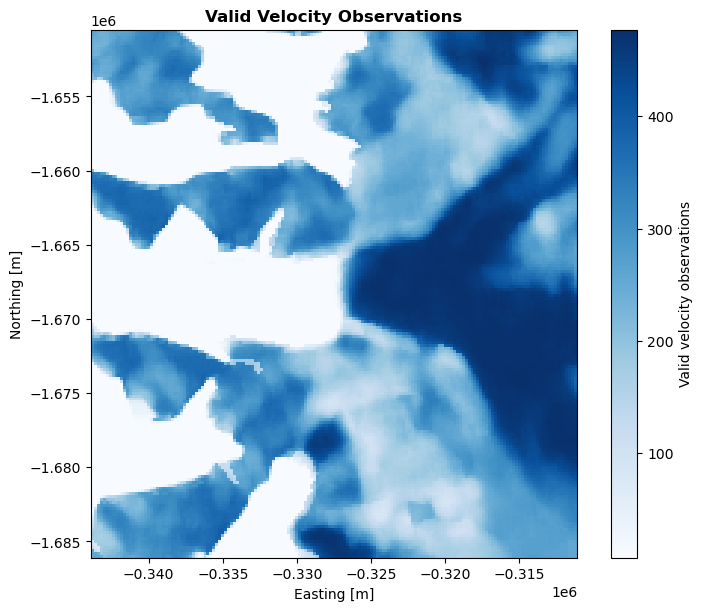

In [5]:
# prepapre velocity data for plotting
x_vals = velocity["x"].values
y_vals = velocity["y"].values

vel_band = (velocity["VelocityMap"].isel(band=2).assign_coords(x=("x", x_vals),  y=("y", y_vals),))
vel_times = pd.to_datetime(vel_band["time"].values)

# valid velocity counts
valid_count = vel_band.count(dim="time")
valid_count_plot = valid_count.where(valid_count > 0) #set 0 count to grey -- have it act as a NaN

# plotting properties for this variable
vprops = varprops["valid_count"]

# plot all time steps
fig, ax = plt.subplots(figsize=(8,6),constrained_layout=True,)
valid_count_plot.plot(ax=ax, x="x", y="y", cmap=vprops["cmap"], add_colorbar=True, cbar_kwargs={"label": vprops["label"]})
ax.set_title("Valid Velocity Observations", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"], )
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
ax.set_aspect("equal")


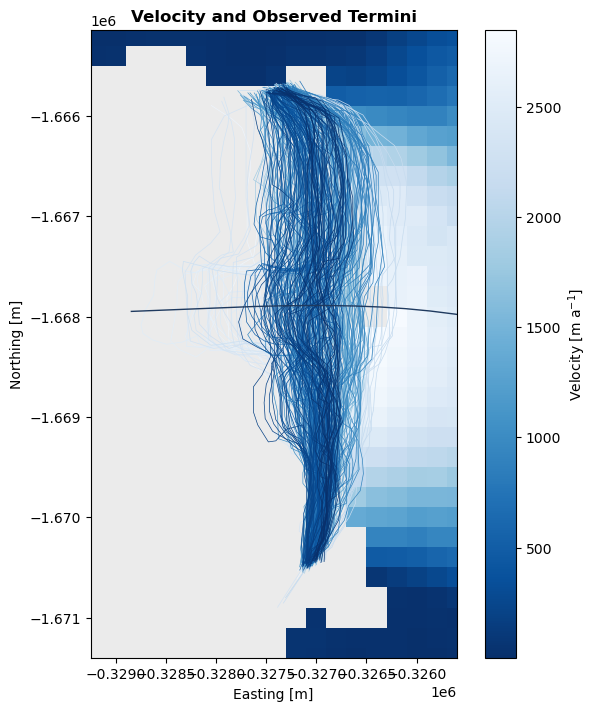

In [6]:
# prepare velocity data for plotting
x_vals = velocity["x"].values
y_vals = velocity["y"].values

vel_band = (velocity["VelocityMap"].isel(band=2).assign_coords(x=("x", x_vals),y=("y", y_vals),))
vel_times = pd.to_datetime(vel_band["time"].values)

# choose representative time index
sampletime = 300
vel_slice = vel_band.isel(time=sampletime)
sample_date = vel_times[sampletime]

# shorthand plotting properties
vprops = varprops["velocity"]
tprops = dataprops["terminus"]
clprops = dataprops["centerline"]
vel_cmap = vprops["cmap"].copy()
vel_cmap.set_bad(c_nan)
terminus_plot = terminus.sort_values("Date").copy()
date_norm = colors.Normalize(vmin=terminus_plot["Date"].min().value,vmax=terminus_plot["Date"].max().value,)
terminus_cmap = tprops["cmap"]

# plot velocity map with observed termini and extended centerline
fig, ax = plt.subplots(figsize=(7,7),constrained_layout=True,)
# velocity map
vel = vel_slice.plot(ax=ax, x="x", y="y", cmap=vel_cmap, add_colorbar=True,cbar_kwargs={"label": vprops["label"]},)
# observed termini, coloured by date
for _, row in terminus_plot.iterrows():
    color = terminus_cmap(date_norm(row["Date"].value))
    gpd.GeoSeries([row.geometry],crs=terminus.crs,).plot(ax=ax,color=color,linewidth=tprops["linewidth"],linestyle=tprops["linestyle"])
# extended centerline
centerline.plot(ax=ax,color=clprops["color"],linewidth=clprops["linewidth"],linestyle=clprops["linestyle"],)

# zoom
xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 500
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

ax.set_title(f"Velocity and Observed Termini", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"])
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
plt.show()

In [7]:
# finding the intersection between the centerline and the terminus
def intersection(centerline, terminus_line):
    intersect = centerline.intersection(terminus_line)

    if intersect.is_empty:
        return None

    if intersect.geom_type == "MultiPoint": #if there is more than one intersect put the point closes to the center of the terminus line
        return min(intersect.geoms, key = lambda p: p.distance(terminus_line.centroid))
    
    return intersect
 
pts = []
for i in range(len(terminus)):
    terminus_line = terminus.geometry.iloc[i]
    pt = intersection(centerline_shape, terminus_line) #geometric intersection between centerline_shape and terminus_line 
    pts.append(pt)

terminus["intersect_points"] = pts

#check to see how many are NaN (i.e. no valid intersection)
none_vals = terminus["intersect_points"].isna().sum()
print(f"Number of NaN intersection points: {none_vals}")

#check to see how many are non NaN (i.e. valid intersection)
valid_vals = terminus["intersect_points"].notna().sum()
print(f"Number of valid intersection points: {valid_vals} out of {len(terminus)}")


Number of NaN intersection points: 0
Number of valid intersection points: 350 out of 350


In [8]:
upstream_m = 1500

vel_at_intersection = []
vel_up_centerline = []

for i in range(len(terminus)):
    pt = terminus["intersect_points"].iloc[i]
    t_term = pd.to_datetime(terminus["Date"].iloc[i])

    if pt is None:
        vel_at_intersection.append(np.nan)
        vel_up_centerline.append(np.nan)
        continue

    vel_slice = vel_band.sel(time=t_term, method="nearest")

    # velocity at intersection
    v0 = vel_slice.sel(x=pt.x, y=pt.y, method="nearest").values
    vel_at_intersection.append(float(v0) if np.isfinite(v0) else np.nan)

    # velocity upstream along the same extended centerline
    d0 = centerline_shape.project(pt)

    v1 = np.nan

    for upstream_m in [1500, 2000]:
        d1 = d0 + upstream_m

        if d1 > centerline_shape.length:
            continue
        p1 = centerline_shape.interpolate(float(d1))
        v_test = vel_slice.sel(x=p1.x,y=p1.y,method="nearest").values

        if np.isfinite(v_test):
            v1 = float(v_test)
            break
    vel_up_centerline.append(v1)

terminus["vel_at_intersection"] = vel_at_intersection
terminus["vel_up_centerline"] = vel_up_centerline


print(f"Number of valid values in vel_at_intersection: {terminus['vel_at_intersection'].notna().sum()} out of {len(terminus)}")
print(f"Number of valid values in vel_up_centerline: {terminus['vel_up_centerline'].notna().sum()} out of {len(terminus)}")

Number of valid values in vel_at_intersection: 88 out of 350
Number of valid values in vel_up_centerline: 341 out of 350


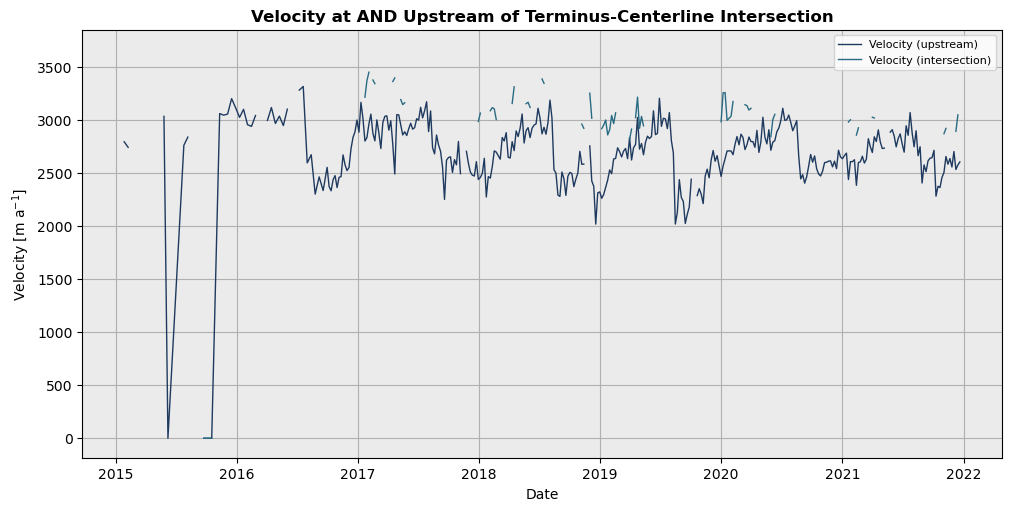

In [9]:
# plot velocity at intersection versus. upstream

# shorthand plotting properties
vprops = varprops["velocity"]
dprops = dataprops["velocity"]

fig, ax = plt.subplots(figsize=(10,5), constrained_layout=True)

# velocity upstream
ax.plot(terminus["Date"], terminus["vel_up_centerline"], label="Velocity (upstream)", color=dprops["color"], linestyle=dprops["linestyle"], linewidth=plotprops["linewidth"])
# velocity at terminus-centerline intersection
ax.plot(terminus["Date"], terminus["vel_at_intersection"], label="Velocity (intersection)", color="#296B82", linestyle="solid", linewidth=plotprops["linewidth"])
ax.set_xlabel("Date")
ax.set_ylabel(vprops["label"])
ax.set_title("Velocity at AND Upstream of Terminus-Centerline Intersection", fontweight = "bold")
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"])
ax.legend(fontsize=plotprops["legendsize"])
plt.show()

In [10]:
def get_centerline_length(terminus, centerline):
    # ensure terminus data type
    if type(terminus) is LineString:
        pass
    if type(terminus) is pd.Series: #if pd take intersection point (from row)
        pt = terminus["intersect_points"]
    elif type(terminus) is gpd.GeoSeries: # if geoseries take single intersection point (from row)
        pt = terminus["intersect_points"].item()
    else: #if else assume it's already a point geometry
        pt = terminus

#same as tayrns code 
    if type(centerline) is LineString:
        pass
    elif type(centerline) is pd.Series:
        centerline_extended = centerline.geometry
    elif type(centerline) is gpd.GeoSeries:
        centerline = centerline.item()

    if pt is None: #if no valid intersection point return nan
        return np.nan
    
    try:
        d = centerline.project(pt) #distance along the centreline from start to the intersection point
        centerline_length = centerline.length - d

    except:
        centerline_length = np.nan #if anything fails (bad geometry, etc.) return nan

    return centerline_length

# calculate glacier length at centerline for each terminus
terminus["Centerline_Length"] = terminus.apply(get_centerline_length, axis = 1, centerline=centerline_shape)
terminus = terminus[terminus["Centerline_Length"].notna()].copy()

# use the first valid terminus as a baseline
terminus["Centerline_Length"] -= terminus["Centerline_Length"].iloc[0]

In [11]:
# observed terminus position
terminus["L"] = terminus["Centerline_Length"]

# time step
terminus["dt_days"] = terminus["Date"].diff().dt.days
terminus["dt_years"] = terminus["dt_days"] / 365.25

# observed change in terminus position
terminus["dL"] = terminus["L"].diff()
terminus["dLdt"] = terminus["dL"] / terminus["dt_years"]

# expected position at t based on previous position + previous velocity * elapsed time
terminus["L_expected"] = (terminus["L"].shift(1) + terminus["vel_up_centerline"].shift(1) * terminus["dt_years"])

# difference between expected and observed position
terminus["expected_minus_observed"] = terminus["L_expected"] - terminus["L"]

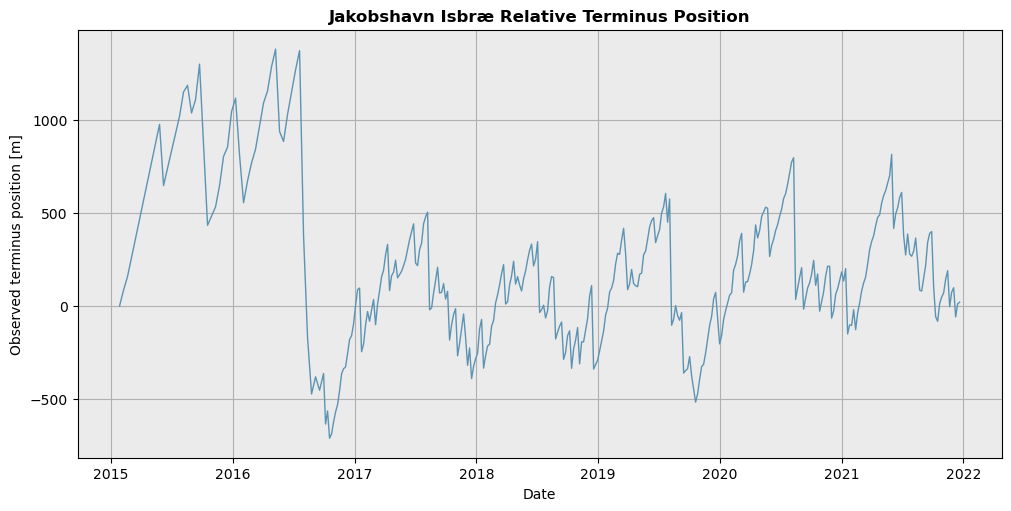

In [12]:
# relative terminus position through time

# shorthand plotting properties
tprops = varprops["observed_terminus_position"]

fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.plot(terminus["Date"], terminus[tprops["variable_name"]], linewidth=plotprops["linewidth"], color ="#5c93b3" )
ax.set_title("Jakobshavn Isbræ Relative Terminus Position", weight ="bold")
ax.set_xlabel("Date")
ax.set_ylabel(tprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"])
plt.show()

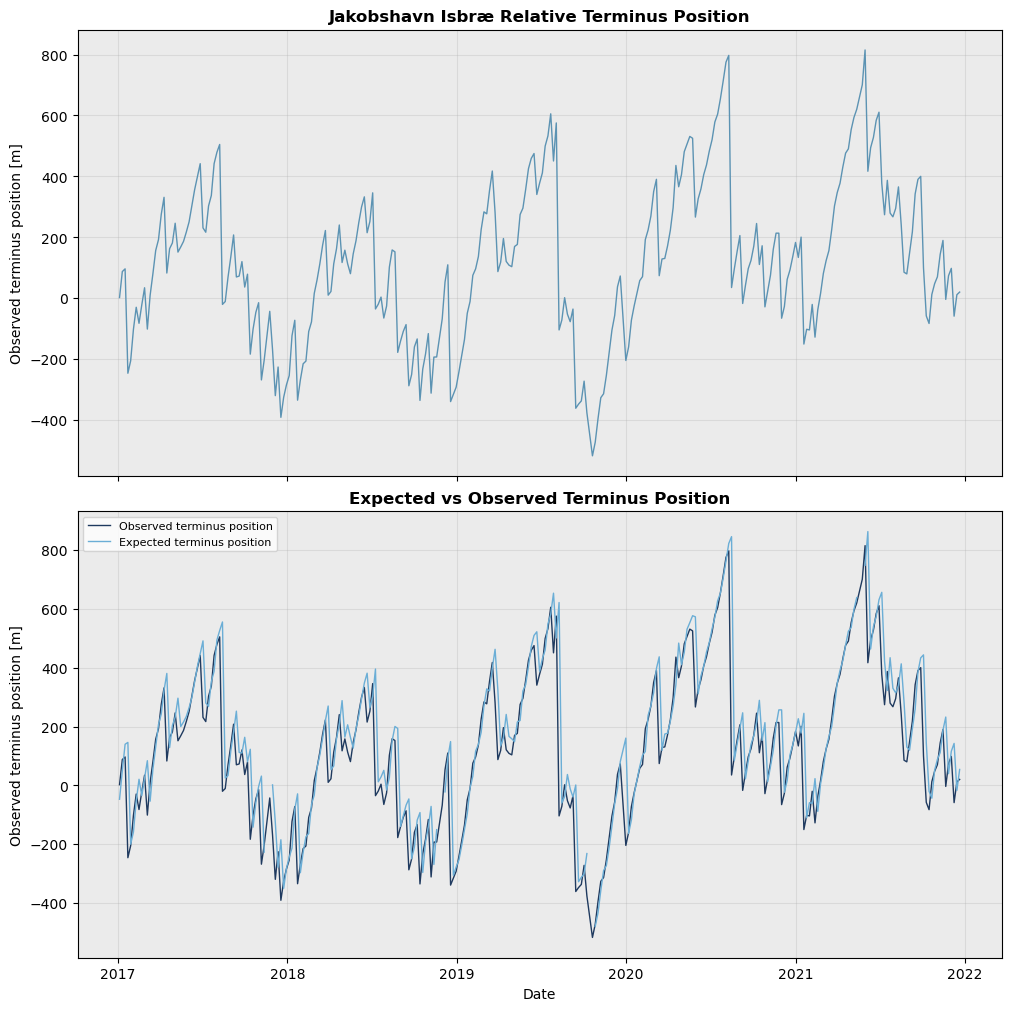

In [13]:
# relative terminus positions and observed vs. predicted

# shorthand plotting properties
tprops = varprops["observed_terminus_position"]
exprops = varprops["expected_terminus_position"]

# cut to 2017 because of limited velocity data before then
terminus_plot = terminus[terminus["Date"] >= "2017"].copy()

fig, ax = plt.subplots(2,1, figsize=(10, 10), constrained_layout=True, sharex=True)

# jakobshavn relative terminus posotion
ax[0].plot(terminus_plot["Date"], terminus_plot[tprops["variable_name"]], linewidth=plotprops["linewidth"], color="#5c93b3")
ax[0].set_title("Jakobshavn Isbræ Relative Terminus Position", fontweight = "bold")
ax[0].set_ylabel(tprops["label"])
ax[0].set_facecolor(plotprops["facecolor"])
ax[0].grid(plotprops["grid"], alpha=0.3)

# expected vs observed terminus position
ax[1].plot(terminus_plot["Date"], terminus_plot[tprops["variable_name"]], linewidth=plotprops["linewidth"], color="#1f3a5f",label=tprops["name"].capitalize())
ax[1].plot(terminus_plot["Date"],terminus_plot[exprops["variable_name"]],linewidth=plotprops["linewidth"],color="#6baed6",label=exprops["name"].capitalize())
ax[1].set_title("Expected vs Observed Terminus Position", fontweight = "bold")
ax[1].set_xlabel("Date")
ax[1].set_ylabel(tprops["label"])
ax[1].set_facecolor(plotprops["facecolor"])
ax[1].grid(plotprops["grid"], alpha=0.3)
ax[1].legend(fontsize=plotprops["legendsize"])
plt.show()


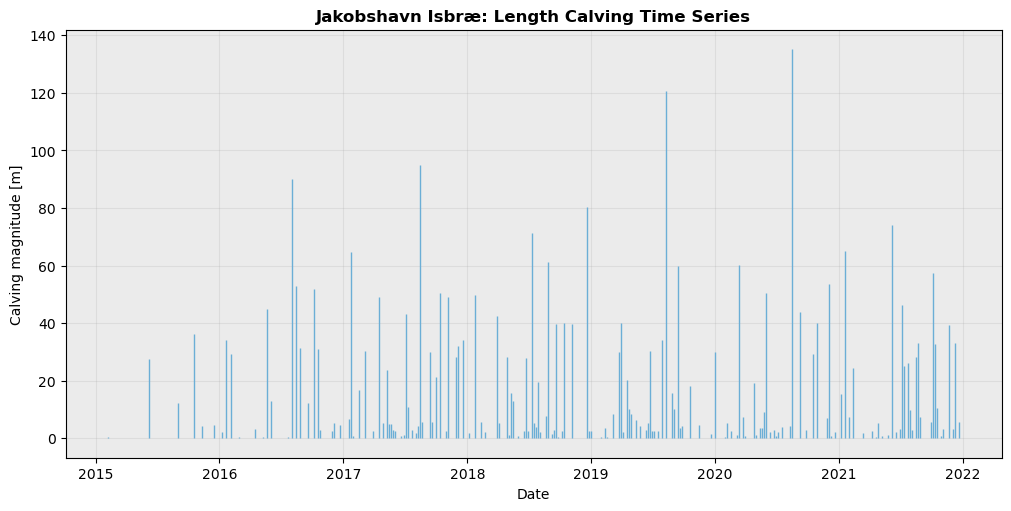

In [41]:
terminus["calving"] = terminus["vel_up_centerline"] - terminus["dLdt"]
terminus["calving_magnitude"] = terminus["calving"]/365.25
#terminus["calving_magnitude"] = (terminus["calving"] * terminus["dt_years"])

#calving time series

# shorthand plotting properties
cprops = varprops["calving_length"]

# mask negative values
terminus["calving_positive"] = (terminus["calving_magnitude"].where(terminus["calving_magnitude"] > 0))

# plot calving magnitudes
fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.vlines(terminus["Date"],ymin=0,ymax=terminus["calving_positive"],linewidth=plotprops["linewidth"],color="#6baed6")
ax.set_title("Jakobshavn Isbræ: Length Calving Time Series", fontweight = "bold")
ax.set_xlabel("Date")
ax.set_ylabel(cprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"], alpha=0.25)
plt.show()

In [42]:
calving_time_series= terminus[["Date", "vel_up_centerline","dLdt","calving","calving_magnitude","dt_days","dt_years", "Centerline_Length"]].copy()
output_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/Jakobshavn-Isbrae-CalvingStatistics/store_calving_length_ts.csv"
calving_time_series.to_csv(output_path, index=False)

In [43]:
# set data paths
bedmachine_path = project_dir / "BedMachine/IllullipSermia/processed/IllulipSermiaBedMachineV7.nc"

# load
bedmachine = xr.open_dataset(bedmachine_path)

# use the extended centerline from the calving analysis
centerline = gpd.GeoDataFrame(geometry=[centerline_shape], crs="EPSG:3413")
centerline_shape = centerline_shape

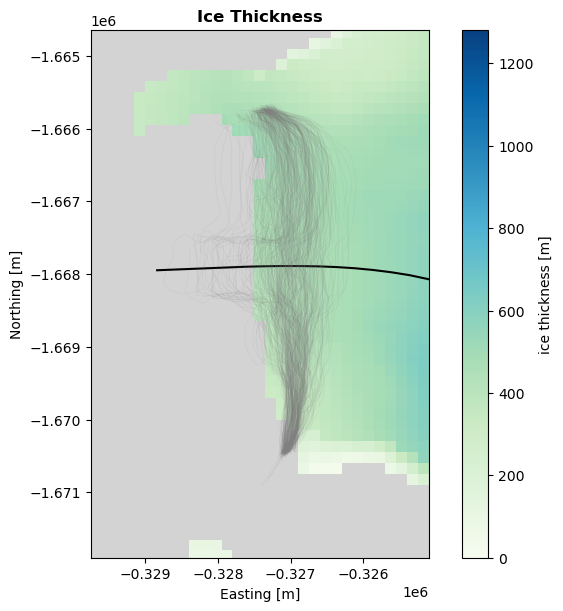

In [44]:
# plotting properties ( 0 m = grey - better for visual)
cmap = plt.colormaps["GnBu"].copy()
cmap.set_bad("lightgrey")
thickness = bedmachine["thickness"].where(bedmachine["thickness"]> 0)

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)

thickness.plot( ax=ax, cmap=cmap, vmin = 0)
centerline.plot(ax=ax, color = "black", linewidth = 1.5)
terminus.plot(ax = ax,color = "gray", linewidth = 0.5, alpha = 0.1)
ax.set_title("Ice Thickness", fontweight = "bold")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.ticklabel_format(axis="both", style="sci", scilimits=(6,6)) 

#zoom
xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 1000
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

plt.show()

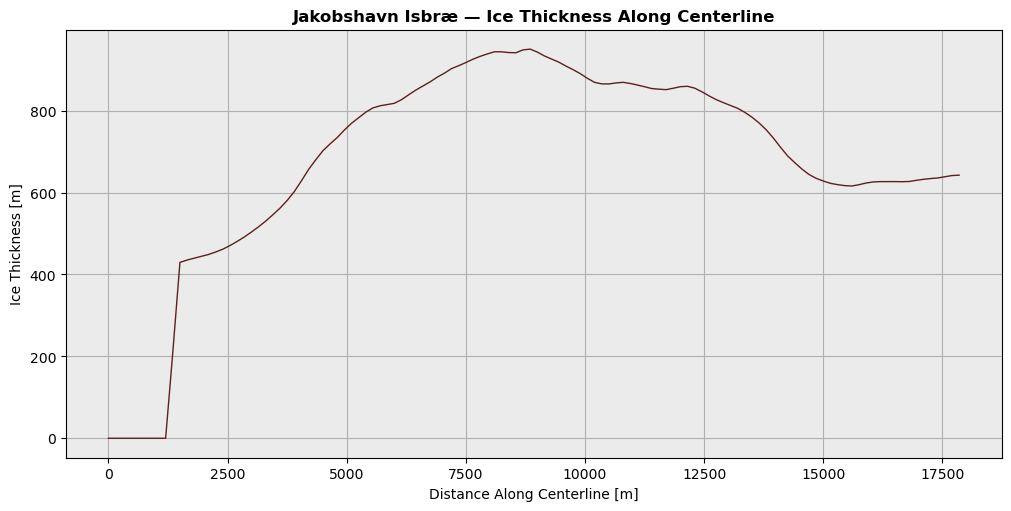

In [45]:
# sample bedmachine values along the centerline using .interp() 
    # goal to get ice thickness, bed elevation, and surface elevation along the centerline

# sample every 150 meters 
spacing = 150 # 150 m bc the BedMachine res is 150 m

# generate distances spaced every 150 m 
distances = np.arange(0, 35000, spacing)

# let these be x and y points 
points = [centerline_shape.interpolate(d)for d in distances]
x_points = np.array([point.x for point in points])
y_points = np.array([point.y for point in points])

# use nearest ice thickness to x/ypoint  - use .sel() - switched to using .interp()
thickness_centerline = bedmachine["thickness"].interp(x=xr.DataArray(x_points, dims="distance"), y=xr.DataArray(y_points, dims="distance"), method="linear")
bed_centerline = bedmachine["bed"].interp(x=xr.DataArray(x_points, dims="distance"), y=xr.DataArray(y_points, dims="distance"), method="linear")
surface_centerline = bedmachine["surface"].interp(x=xr.DataArray(x_points, dims="distance"), y=xr.DataArray(y_points, dims="distance"), method="linear")

# create profiles
thickness_profile = thickness_centerline.values
bed_profile = bed_centerline.values
surface_profile = surface_centerline.values

# surface elevation =  bed + thickness
surface_calculated = bed_profile + thickness_profile

bedmachine_profile = pd.DataFrame({
    "distance_m": distances,
    "x": x_points,
    "y": y_points,
    "thickness_m": thickness_profile,
    "bed_m": bed_profile,
    "surface_m": surface_profile,
    "surface_calculated_m": surface_calculated
})

fig, ax = plt.subplots(figsize = (10,5), constrained_layout = True)
ax.plot(bedmachine_profile["distance_m"], bedmachine_profile["thickness_m"], color="#5f1f1f", linewidth = plotprops["linewidth"])
ax.set_xlabel("Distance Along Centerline [m]")
ax.set_ylabel("Ice Thickness [m]")
ax.set_title("Jakobshavn Isbræ — Ice Thickness Along Centerline", fontweight=plotprops["titleweight"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(True)
plt.show()

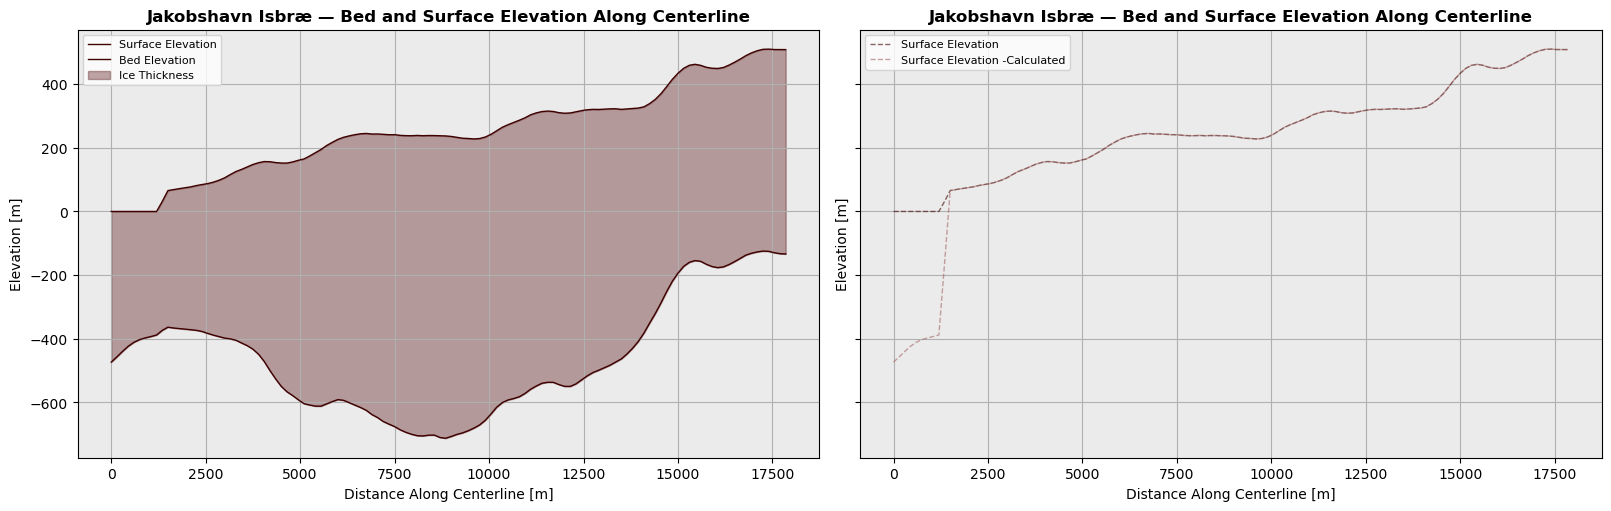

In [46]:
fig, ax = plt.subplots(1,2, figsize = (16,5), constrained_layout = True, sharex = True, sharey= True)


# plot 1 bed & surface elevation, and then fill would be thickness
# bed elevation + thickness = surface elevation
ax[0].plot(bedmachine_profile["distance_m"], bedmachine_profile["surface_m"], color="#3e0000", linewidth = plotprops["linewidth"], label="Surface Elevation")
ax[0].plot(bedmachine_profile["distance_m"], bedmachine_profile["bed_m"], color="#3e0000", linewidth = plotprops["linewidth"], label="Bed Elevation")
ax[0].fill_between(bedmachine_profile["distance_m"], bedmachine_profile["bed_m"], bedmachine_profile["surface_m"], color="#5f1f1f", alpha=0.4, label="Ice Thickness")

# plot 2 would be comparing observed surface elevation vs calculated surface elevation (bed + thickness)
ax[1].plot(bedmachine_profile["distance_m"], bedmachine_profile["surface_m"], color="#3e0000", linewidth = plotprops["linewidth"], linestyle = "--", alpha = 0.6, label = "Surface Elevation")
ax[1].plot(bedmachine_profile["distance_m"], bedmachine_profile["surface_calculated_m"], color="#a36666", linewidth = plotprops["linewidth"], linestyle = "--",alpha = 0.6, label = "Surface Elevation -Calculated")


for a in ax:
    a.set_xlabel("Distance Along Centerline [m]")
    a.set_ylabel("Elevation [m]")
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True)
    a.legend(fontsize=plotprops["legendsize"])
    a.set_title("Jakobshavn Isbræ — Bed and Surface Elevation Along Centerline", fontweight=plotprops["titleweight"])

In [47]:
# change intersect_points from string to shapely points (better for geospatial)
terminus["intersect_points"] = terminus["intersect_points"].apply(lambda p: wkt.loads(p) if isinstance(p, str) else p)
print(type(terminus["intersect_points"].iloc[0]))

# get intersection coordinates
x_points = [p.x for p in terminus["intersect_points"]]
y_points = [p.y for p in terminus["intersect_points"]]

# sample nearest BedMachine thickness
terminus["thickness_at_terminus"] = bedmachine["thickness"].interp(x=xr.DataArray(x_points, dims="point"), y=xr.DataArray(y_points, dims="point"), method="nearest").values

<class 'shapely.geometry.point.Point'>


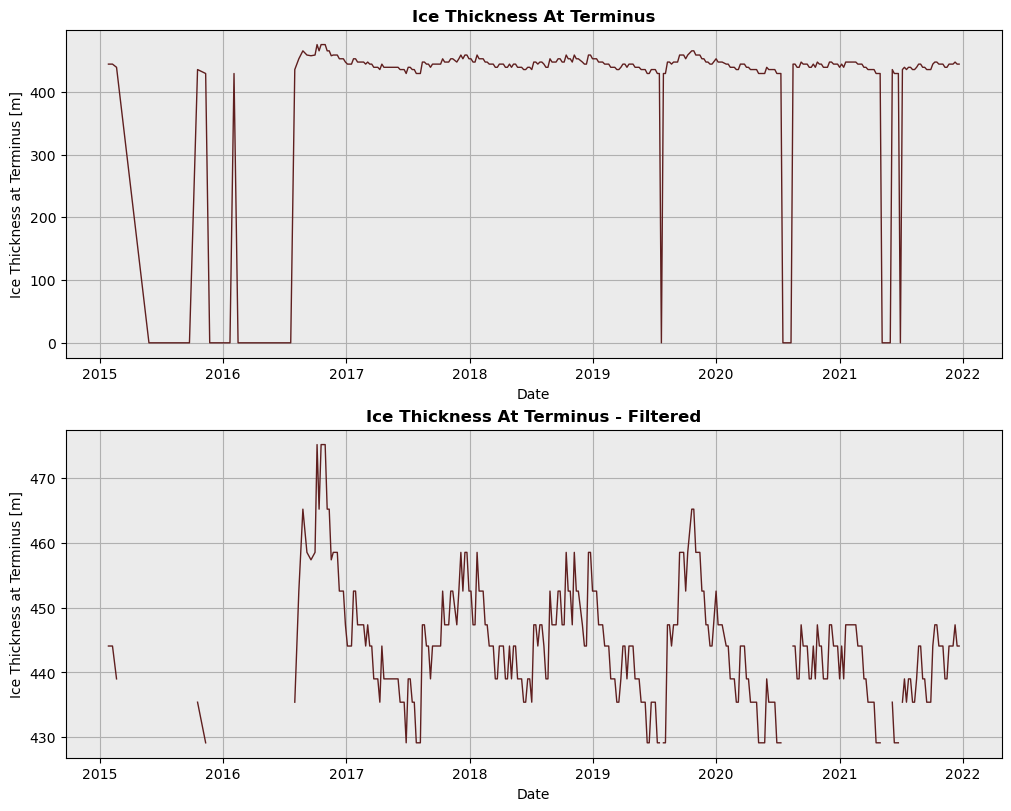

In [48]:
terminus_filtered = terminus.copy()
terminus_filtered["thickness_at_terminus"] = terminus_filtered["thickness_at_terminus"].replace(0, np.nan)

fig, ax = plt.subplots(2, 1, figsize = (10,8), constrained_layout = True)
ax[0].plot(terminus["Date"], terminus["thickness_at_terminus"], color="#5f1f1f", linewidth = plotprops["linewidth"])
ax[0].set_xlabel("Date")
ax[0].set_ylabel("Ice Thickness at Terminus [m]")
ax[0].set_title("Ice Thickness At Terminus", fontweight=plotprops["titleweight"])

ax[1].plot(terminus_filtered["Date"], terminus_filtered["thickness_at_terminus"], color="#5f1f1f", linewidth = plotprops["linewidth"])
ax[1].set_xlabel("Date")
ax[1].set_ylabel("Ice Thickness at Terminus [m]")
ax[1].set_title("Ice Thickness At Terminus - Filtered", fontweight=plotprops["titleweight"])

for a in ax.flat:
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True)
plt.show()

count    165.000000
mean       0.042235
std        0.054124
min        0.000102
25%        0.005446
50%        0.012820
75%        0.068130
max        0.304366
dtype: float64


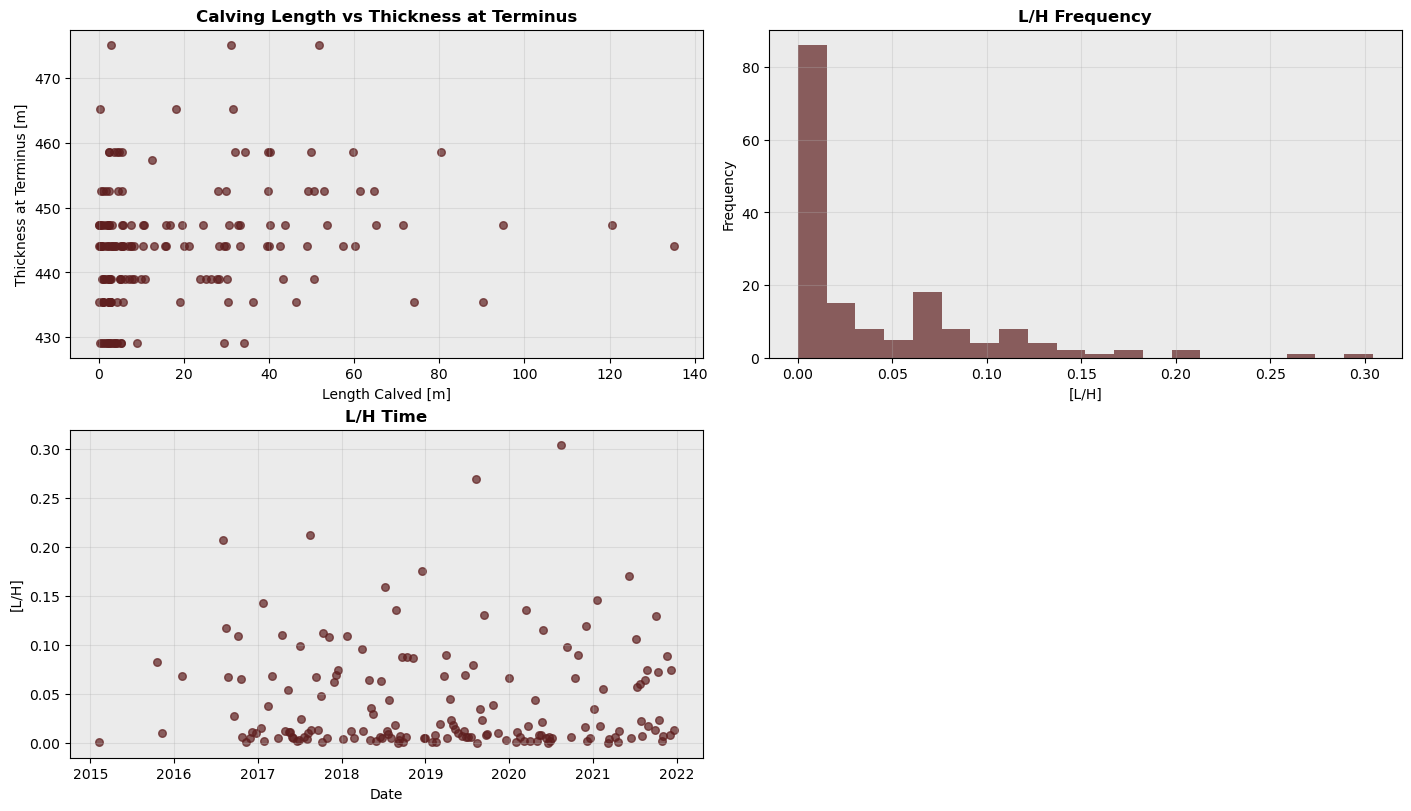

In [49]:
# L/H - length calved/thickness at terminus position
    # goal is some form of understanding as to how the thickness at the terminus position relates to the length calved

L_H_ratio = (terminus_filtered["calving_positive"] / terminus_filtered["thickness_at_terminus"])

# statistics
print(L_H_ratio.describe())

fig, ax = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)

# calving length vs thickness at terminus
ax[0,0].scatter(terminus_filtered["calving_positive"], terminus_filtered["thickness_at_terminus"], color="#5f1f1f", s=30, alpha=0.7)
ax[0,0].set_xlabel("Length Calved [m]")
ax[0,0].set_ylabel("Thickness at Terminus [m]")
ax[0,0].set_title("Calving Length vs Thickness at Terminus", fontweight=plotprops["titleweight"])
ax[0,0].set_facecolor(plotprops["facecolor"])
ax[0,0].grid(True, alpha=0.3)

# frequency/distribution of L/H ratio
ax[0,1].hist(L_H_ratio, bins=20, color="#5f1f1f", alpha=0.7)
ax[0,1].set_xlabel("[L/H]")
ax[0,1].set_ylabel("Frequency")
ax[0,1].set_title("L/H Frequency", fontweight=plotprops["titleweight"])
ax[0,1].set_facecolor(plotprops["facecolor"])
ax[0,1].grid(True, alpha=0.3)

# L/H ratio through time
ax[1,0].scatter(terminus_filtered["Date"], L_H_ratio, color="#5f1f1f", s=30, alpha=0.7)
ax[1,0].set_xlabel("Date")
ax[1,0].set_ylabel("[L/H]")
ax[1,0].set_title( "L/H Time", fontweight=plotprops["titleweight"])
ax[1,0].set_facecolor(plotprops["facecolor"])
ax[1,0].grid(True, alpha=0.3)

# unused panel
ax[1, 1].axis("off")

plt.show()




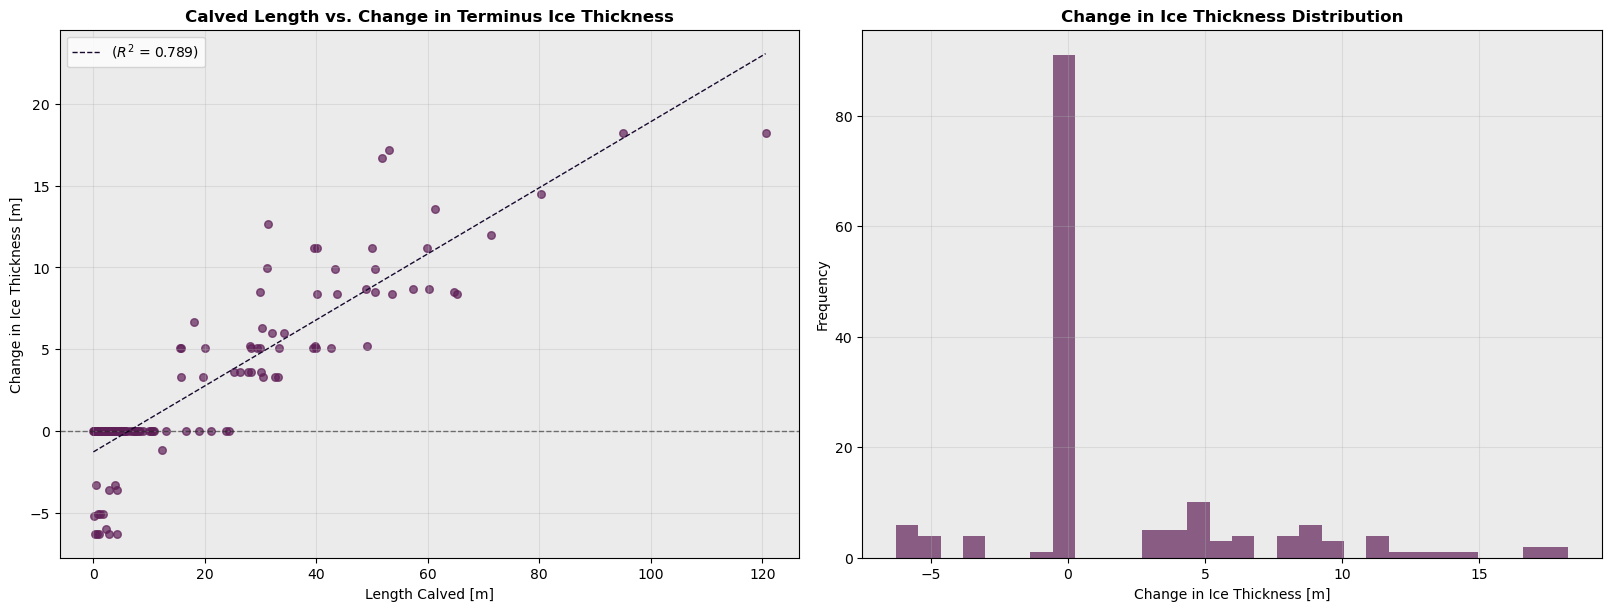

In [50]:
# Is there a way to better visualise ice thickness vs length calvedd - normalisation of some form could help 
    # Could we look at comparing the change in ice thickness relative to the previous terminus position and then compare that to the length calved?
        # Bc in essence the length calved is the change in terminus position - so this would be just a change in L and a change in H - and that would make it comparable??

# change in thickness H relative to previous terminus position
terminus_change = terminus.sort_values("Date").reset_index(drop=True)

# previous terminus thickness
terminus_change["previous_thickness"] = (terminus_change["thickness_at_terminus"].shift(1)) #shift to previous terminus thickness
# change in thickness between consecutive terminus positions
terminus_change["delta_thickness"] = (terminus_change["thickness_at_terminus"] - terminus_change["previous_thickness"])

filter = ((terminus_change["thickness_at_terminus"] > 0) & (terminus_change["previous_thickness"] > 0) & (terminus_change["calving_positive"].notna()) & (terminus_change["delta_thickness"].notna()))
terminus_change = terminus_change[filter].copy()
terminus_change[["Date", "thickness_at_terminus", "previous_thickness", "delta_thickness"]].head()

# linear correlation??

linear_corr = linregress(terminus_change["calving_positive"], terminus_change["delta_thickness"])
slope = linear_corr.slope
intercept = linear_corr.intercept
r_2 = linear_corr.rvalue**2
x_trend = np.linspace(terminus_change["calving_positive"].min(), terminus_change["calving_positive"].max(), 100)
y_trend = slope * x_trend + intercept

# plot attempt

fig, ax = plt.subplots(1, 2, figsize=(16,6), constrained_layout=True)

ax[0].scatter(terminus_change["calving_positive"], terminus_change["delta_thickness"], color="#5f1f57", s=30, alpha = 0.7)
ax[0].plot(x_trend, y_trend, color="#18092e", linewidth=1, linestyle = "--", label=f"($R^2$ = {r_2:.3f})")
ax[0].axhline(y=0, color="black", linewidth=1, linestyle="--", alpha=0.5)
ax[0].set_xlabel("Length Calved [m]")
ax[0].set_ylabel("Change in Ice Thickness [m]")
ax[0].set_title("Calved Length vs. Change in Terminus Ice Thickness", fontweight=plotprops["titleweight"])
ax[0].set_facecolor(plotprops["facecolor"])
ax[0].grid(True, alpha=0.3)
ax[0].legend()


# larger positive changes in ice thickness are associated with larger calving events - kinda.

ax[1].hist(terminus_change["delta_thickness"], bins=30, color="#5f1f57", alpha=0.7)
ax[1].set_xlabel("Change in Ice Thickness [m]")
ax[1].set_ylabel("Frequency")
ax[1].set_title("Change in Ice Thickness Distribution", fontweight=plotprops["titleweight"])
ax[1].set_facecolor(plotprops["facecolor"])
ax[1].grid(True, alpha=0.3)

plt.show()


# small calving lengths generally correspond to thickness differences near zero.
# medium calving lengths tend to have increasingly positive thickness differences.
# large calving lengths are associated with an array of thicnkess values - both +ve and -ve


# BUT BUT BUT
# the calved length and delta thickness are both related to terminus displacement - so this is not an independent relationship.
    # i.e., some of this relationship is likely due to the fact that larger calving events are associated with larger terminus displacements
    #  which in turn are associated with larger changes in ice thickness at the terminus.


#so maybe this is useless

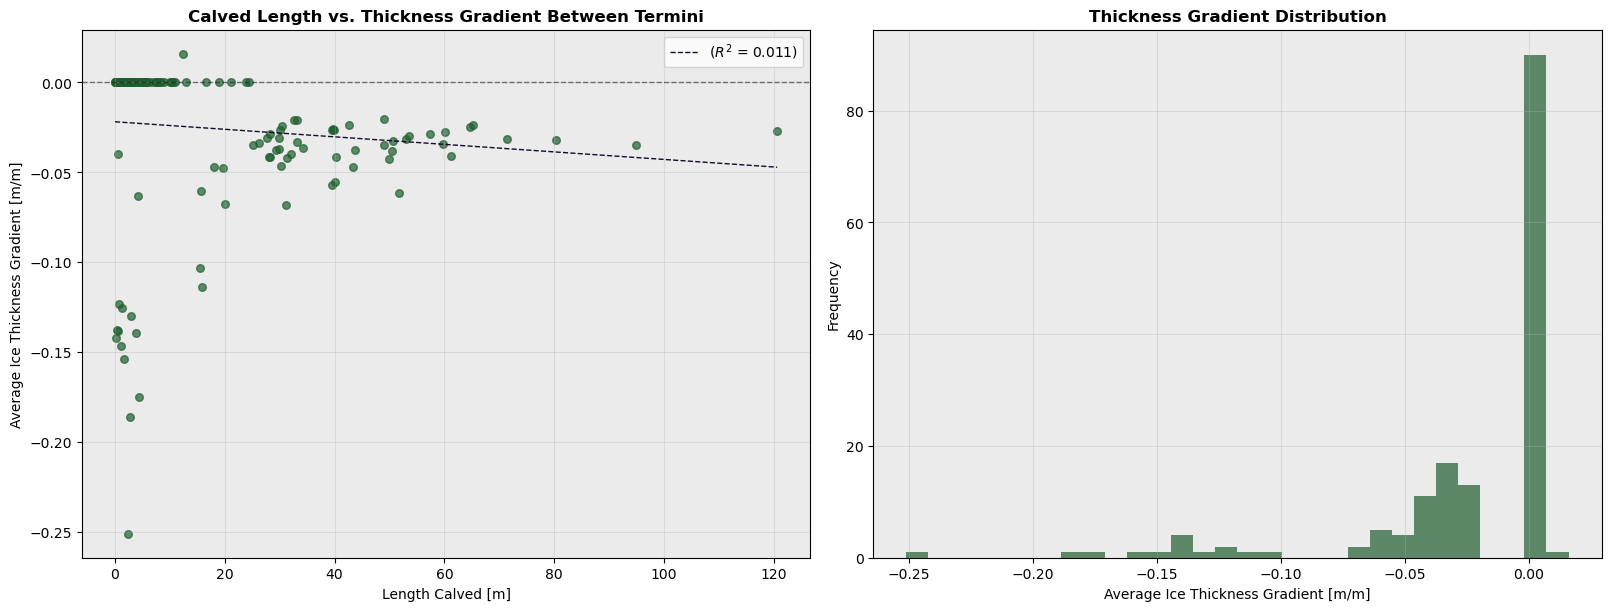

In [51]:
# Could also look at potentially the gradient of ice thickness between successive terminus positions and then compare that to the length calved
    # i think that would be interesting - like maybe

# would be able to apply the same methodlogy as above 

# sort date and reset index
terminus_change = terminus.sort_values("Date").reset_index(drop=True).copy()

# previous terminus thickness
terminus_change["previous_thickness"] = (terminus_change["thickness_at_terminus"].shift(1)) #shift to previous terminus thickness
# change in thickness between consecutive terminus positions
terminus_change["delta_thickness"] = (terminus_change["thickness_at_terminus"] - terminus_change["previous_thickness"])

# change in terminus position along centerline
terminus_change["dL"] = (terminus_change["Centerline_Length"] - terminus_change["Centerline_Length"].shift(1))

# calculate thickness gradient (dH/dL)
terminus_change["thickness_gradient"] = (terminus_change["delta_thickness"] / terminus_change["dL"])

# Filter invalid observations
filter = ((terminus_change["thickness_at_terminus"] > 0) & (terminus_change["previous_thickness"] > 0) & (terminus_change["calving_positive"].notna()) &(terminus_change["dL"].notna()) & (terminus_change["dL"] != 0) & (terminus_change["thickness_gradient"].notna()) & np.isfinite(terminus_change["thickness_gradient"]))
terminus_gradient = terminus_change.loc[filter].copy()

terminus_gradient[["Date", "calving_positive", "dL", "delta_thickness", "thickness_gradient"]].head()

linear_corr = linregress(terminus_gradient["calving_positive"], terminus_gradient["thickness_gradient"])
slope = linear_corr.slope
intercept = linear_corr.intercept
r_2 = linear_corr.rvalue**2
x_trend = np.linspace(terminus_gradient["calving_positive"].min(), terminus_gradient["calving_positive"].max(), 100)
y_trend = slope * x_trend + intercept

# plot thickness gradient vs calved length - both in m

fig, ax = plt.subplots(1,2, figsize=(16, 6), constrained_layout=True)
ax[0].scatter(terminus_gradient["calving_positive"],terminus_gradient["thickness_gradient"], color="#1f5f2f", s=30, alpha=0.7)
ax[0].axhline( y=0, color="black", linewidth=1, linestyle="--", alpha=0.5)
ax[0].plot(x_trend, y_trend, color="#18092e", linewidth=1, linestyle = "--", label=f"($R^2$ = {r_2:.3f})")
ax[0].set_xlabel("Length Calved [m]")
ax[0].set_ylabel("Average Ice Thickness Gradient [m/m]")
ax[0].set_title( "Calved Length vs. Thickness Gradient Between Termini",  fontweight=plotprops["titleweight"])
ax[0].set_facecolor(plotprops["facecolor"])
ax[0].grid(True, alpha=0.3)
ax[0].legend()


# plot thickness gradient distribution
ax[1].hist(terminus_gradient["thickness_gradient"], bins=30, color="#1f5f2f", alpha=0.7)
ax[1].set_xlabel("Average Ice Thickness Gradient [m/m]")
ax[1].set_ylabel("Frequency")
ax[1].set_title("Thickness Gradient Distribution", fontweight=plotprops["titleweight"])
ax[1].set_facecolor(plotprops["facecolor"])
ax[1].grid(True, alpha=0.3)

plt.show()


# my false hope of a relationship between the thickness gradient and the length calved is not really there 
    # this tells me that it was because of the change in temrinus psotion and not because of the thickness gradient between the two positions 

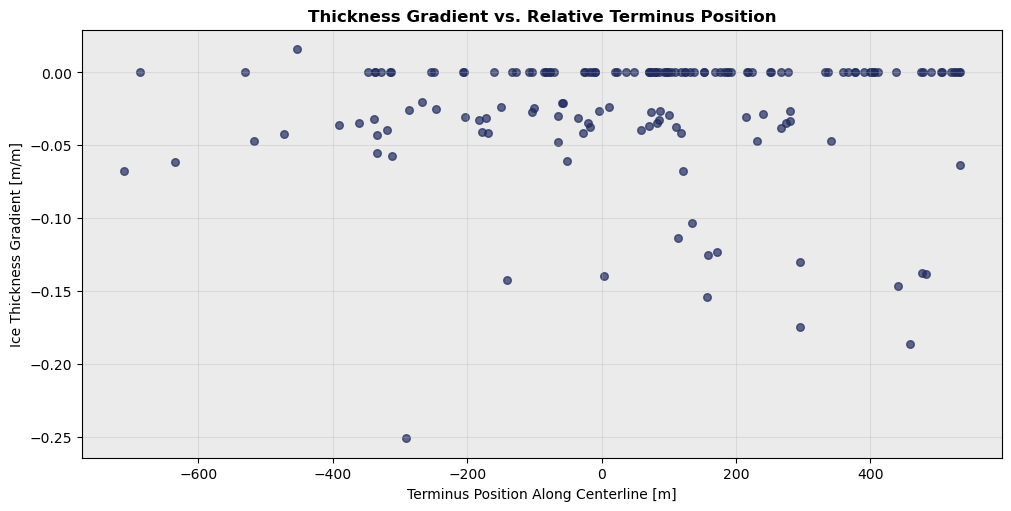

In [52]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

ax.scatter(terminus_gradient["Centerline_Length"], terminus_gradient["thickness_gradient"],color="#1f2b5f", s=30, alpha=0.7)
ax.set_xlabel("Terminus Position Along Centerline [m]")
ax.set_ylabel("Ice Thickness Gradient [m/m]")
ax.set_title( "Thickness Gradient vs. Relative Terminus Position", fontweight=plotprops["titleweight"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(True, alpha=0.3)

plt.show()

# this tells me that thickness is related to where the terminus is along the centerline - which makes sense. 


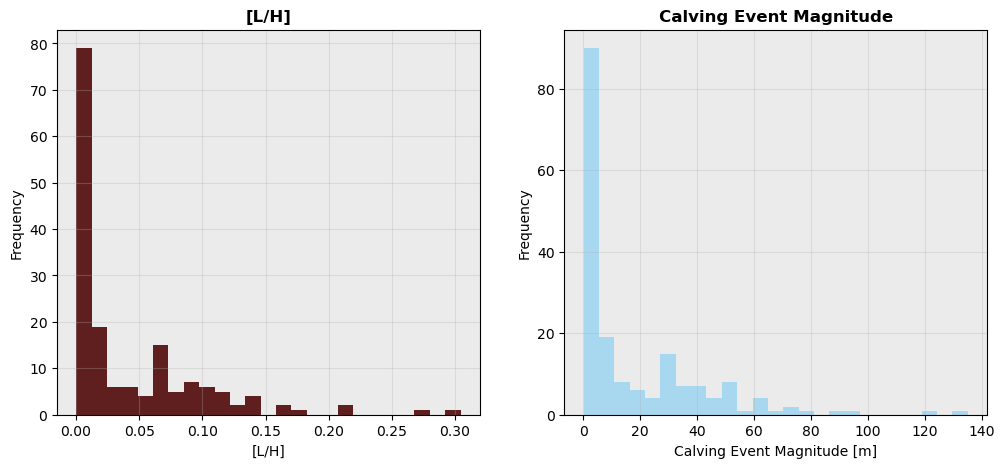

In [53]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))

ax[0].hist(L_H_ratio, bins = 25, color = "#5f1f1f")
ax[0].set_xlabel("[L/H]")
ax[0].set_ylabel("Frequency")
ax[0].set_title("[L/H]", fontweight = plotprops["titleweight"])

ax[1].hist(terminus["calving_positive"], bins = 25, color = "#A8D8F0")
ax[1].set_xlabel("Calving Event Magnitude [m]")
ax[1].set_ylabel("Frequency")
ax[1].set_title("Calving Event Magnitude", fontweight = plotprops["titleweight"])

for a in ax:
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True, alpha = 0.3 )


In [54]:
# bed — bed elevation (bed topography) relative to the geoid (m) - where geoid = surface that closely matches the sea level 
    # so we can take the bed = - water depth 
# so we can calculated the cliff height = ice thickness - depth 

# extract bed elevation at each terminus position
terminus["bed_at_terminus"] = bedmachine["bed"].sel(x=xr.DataArray(x_points, dims="point"), y=xr.DataArray(y_points, dims="point"), method="nearest").values

# bed — bed elevation (bed topography) relative to the geoid (m) - where geoid = surface that closely matches the sea level 
    # so we can take the bed = - water depth 
terminus["water_depth"] = (-terminus["bed_at_terminus"])
terminus["cliff_height"] = terminus["thickness_at_terminus"] - terminus["water_depth"].clip(lower=0)

terminus[["Date", "thickness_at_terminus", "bed_at_terminus", "water_depth", "cliff_height"]].head()
#filter out values or now 
terminus_cliff = terminus[(terminus["cliff_height"] > 0) & (terminus["cliff_height"].notna())].copy()

# normalize calving magnitude by cliff height
terminus_cliff["L_cliff_ratio"] = (terminus_cliff["calving_positive"] / terminus_cliff["cliff_height"])

count    165.000000
mean       0.254258
std        0.325341
min        0.000622
25%        0.034368
50%        0.084032
75%        0.405668
max        1.854233
Name: L_cliff_ratio, dtype: float64


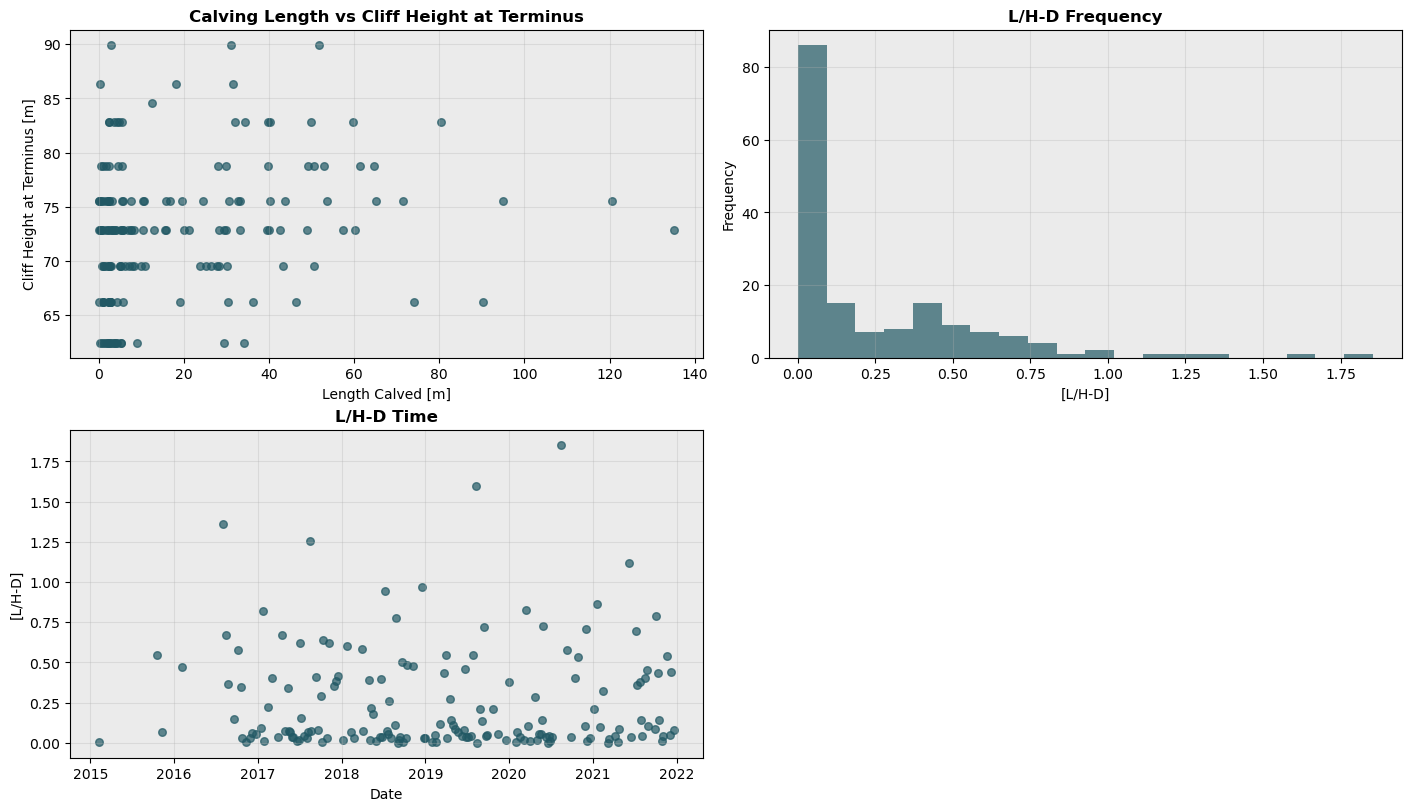

In [55]:
# statistics
print(terminus_cliff["L_cliff_ratio"].describe())

fig, ax = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)

# calving length vs cliff height at terminus
ax[0,0].scatter(terminus_cliff["calving_positive"], terminus_cliff["cliff_height"], color="#215864", s=30, alpha=0.7)
ax[0,0].set_xlabel("Length Calved [m]")
ax[0,0].set_ylabel("Cliff Height at Terminus [m]")
ax[0,0].set_title("Calving Length vs Cliff Height at Terminus", fontweight=plotprops["titleweight"])
ax[0,0].set_facecolor(plotprops["facecolor"])
ax[0,0].grid(True, alpha=0.3)

# frequency/distribution of L/H ratio
ax[0,1].hist(terminus_cliff["L_cliff_ratio"], bins=20, color="#215864", alpha=0.7)
ax[0,1].set_xlabel("[L/H-D]")
ax[0,1].set_ylabel("Frequency")
ax[0,1].set_title("L/H-D Frequency", fontweight=plotprops["titleweight"])
ax[0,1].set_facecolor(plotprops["facecolor"])
ax[0,1].grid(True, alpha=0.3)

# L/H ratio through time
ax[1,0].scatter(terminus_cliff["Date"], terminus_cliff["L_cliff_ratio"], color="#215864", s=30, alpha=0.7)
ax[1,0].set_xlabel("Date")
ax[1,0].set_ylabel("[L/H-D]")
ax[1,0].set_title( "L/H-D Time", fontweight=plotprops["titleweight"])
ax[1,0].set_facecolor(plotprops["facecolor"])
ax[1,0].grid(True, alpha=0.3)

# unused panel
ax[1, 1].axis("off")

plt.show()


# seasonal variation in L/H ratio - you would expect this bc it would be higher in the summer - bc calved length is higher but also would thickness be higher too bc its further retreated?

# not a large apparent relationship between L/H thickness and length calved

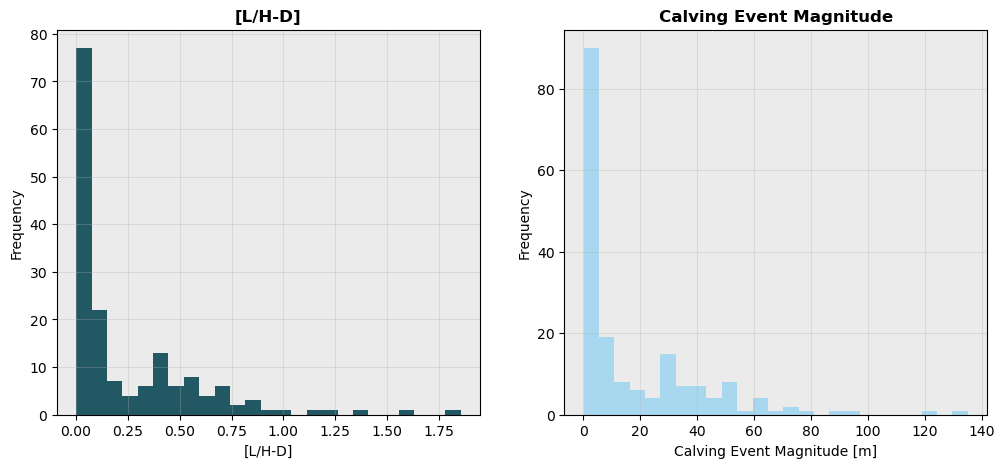

In [56]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))

ax[0].hist(terminus_cliff["L_cliff_ratio"], bins = 25, color = "#215864")
ax[0].set_xlabel("[L/H-D]")
ax[0].set_ylabel("Frequency")
ax[0].set_title("[L/H-D]", fontweight = plotprops["titleweight"])

ax[1].hist(terminus["calving_positive"], bins = 25, color = "#A8D8F0")
ax[1].set_xlabel("Calving Event Magnitude [m]")
ax[1].set_ylabel("Frequency")
ax[1].set_title("Calving Event Magnitude", fontweight = plotprops["titleweight"])

for a in ax:
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True, alpha = 0.3 )


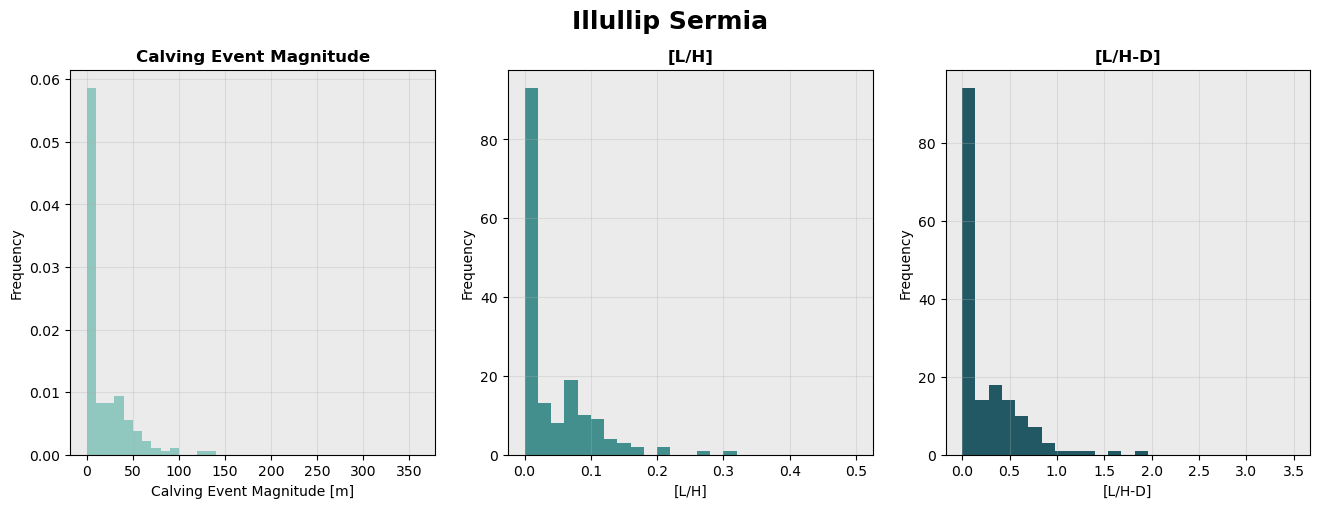

In [67]:
calving_bins = np.arange(0, 370, 10)
LH_bins = np.linspace(0, 0.5, 26)
cliff_bins = np.linspace(0, 3.5, 26)

fig, ax = plt.subplots(1, 3, figsize = (16, 5))

ax[0].hist(terminus["calving_positive"], bins = calving_bins, density=True,  color = "#90C7BE")
ax[0].set_xlabel("Calving Event Magnitude [m]")
ax[0].set_ylabel("Frequency")
ax[0].set_title("Calving Event Magnitude", fontweight = plotprops["titleweight"])

ax[1].hist(L_H_ratio, bins= LH_bins, color = "#438F8E")
ax[1].set_xlabel("[L/H]")
ax[1].set_ylabel("Frequency")
ax[1].set_title("[L/H]", fontweight = plotprops["titleweight"])

ax[2].hist(terminus_cliff["L_cliff_ratio"], bins = cliff_bins, color = "#215864")
ax[2].set_xlabel("[L/H-D]")
ax[2].set_ylabel("Frequency")
ax[2].set_title("[L/H-D]", fontweight = plotprops["titleweight"])

fig.suptitle("Illullip Sermia", fontsize=18, fontweight="bold", y=1.001)

for a in ax:
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True, alpha = 0.3 )